# Hitomezashi

Hitomezashi is a kind of Japanese sashiko embroidery: running stitches along every row and every
column of a grid. Each line starts either with a stitch or with a gap, and one random bit per
line decides which. The stitches enclose a maze of regions that can always be colored with just
two colors, here indigo and sand, with the stitches in ivory.

In [1]:
import random

from common import polygon
from nbturtle import render

W = H = 800
N = 32
CELL = W / N
SEED = 14
INDIGO = "#1e2d66"
SAND = "#efe3cd"
IVORY = "#f6f1e6"
STITCH = 3

## One bit per line

`bits()` makes a random bit for each of the 32 rows, and again for the 32 columns. Each list gets
an even number of ones. Then crossing the whole tile flips the color an even number of times, so
the colors match where the tile wraps around.

In [2]:
def bits():
    b = [random.randrange(2) for _ in range(N)]
    if sum(b) % 2:
        b[0] ^= 1
    return b


random.seed(SEED)
rows, cols = bits(), bits()
print("rows", "".join(map(str, rows)))
print("cols", "".join(map(str, cols)))

rows 00111011111010111100100001001011
cols 00010010110111000110001001101111


## The stitches

On horizontal line `j`, the stitch from column `i` to `i + 1` is there when `i + rows[j]` is
even, so stitches and gaps alternate and the bit decides which comes first. Vertical lines work
the same way with `cols`.

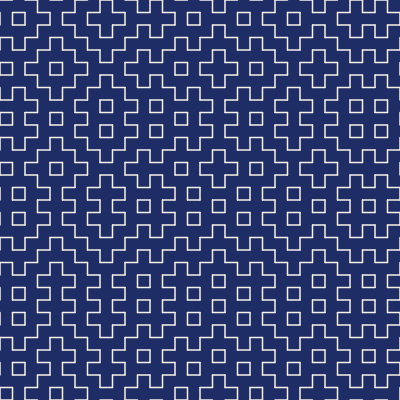

In [3]:
def stitches(t):
    t.pensize(STITCH)
    t.pencolor(IVORY)
    for j in range(N + 1):
        y = -H / 2 + j * CELL
        for i in range(N):
            if (i + rows[j % N]) % 2 == 0:
                t.goto(-W / 2 + i * CELL, y)
                t.pendown()
                t.goto(-W / 2 + (i + 1) * CELL, y)
                t.penup()
    for i in range(N + 1):
        x = -W / 2 + i * CELL
        for j in range(N):
            if (j + cols[i % N]) % 2 == 0:
                t.goto(x, -H / 2 + j * CELL)
                t.pendown()
                t.goto(x, -H / 2 + (j + 1) * CELL)
                t.penup()


render(stitches, W, H, INDIGO, dpi=36)

## Two colors

Walk along the bottom row and flip the color every time you cross a stitch, then walk up each
column the same way. Every cell gets a color, and the cells on either side of a stitch always
differ. `polygon` fills each cell and outlines it in its own color, which hides the hairline
gaps between neighbours.

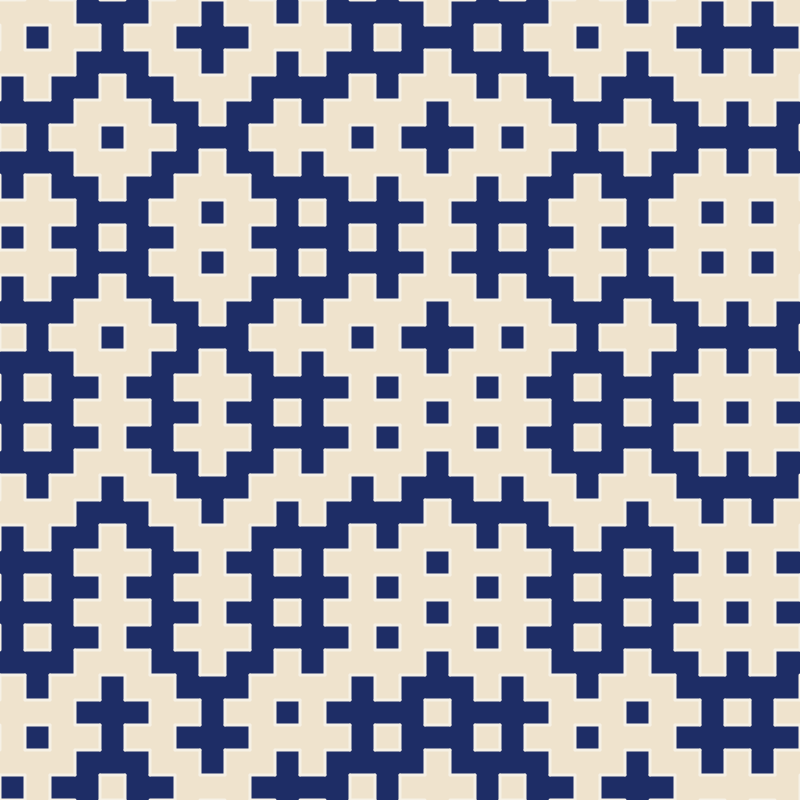

In [4]:
def coloring():
    color = {(0, 0): 0}
    for i in range(1, N):
        color[(i, 0)] = color[(i - 1, 0)] ^ ((0 + cols[i]) % 2 == 0)
    for i in range(N):
        for j in range(1, N):
            color[(i, j)] = color[(i, j - 1)] ^ ((i + rows[j]) % 2 == 0)
    return color


def draw(t):
    for (i, j), c in coloring().items():
        x, y = -W / 2 + i * CELL, -H / 2 + j * CELL
        polygon(t, [(x, y), (x + CELL, y), (x + CELL, y + CELL), (x, y + CELL)], SAND if c else INDIGO)
    stitches(t)


canvas = render(draw, W, H, INDIGO)
canvas

## Does it repeat?

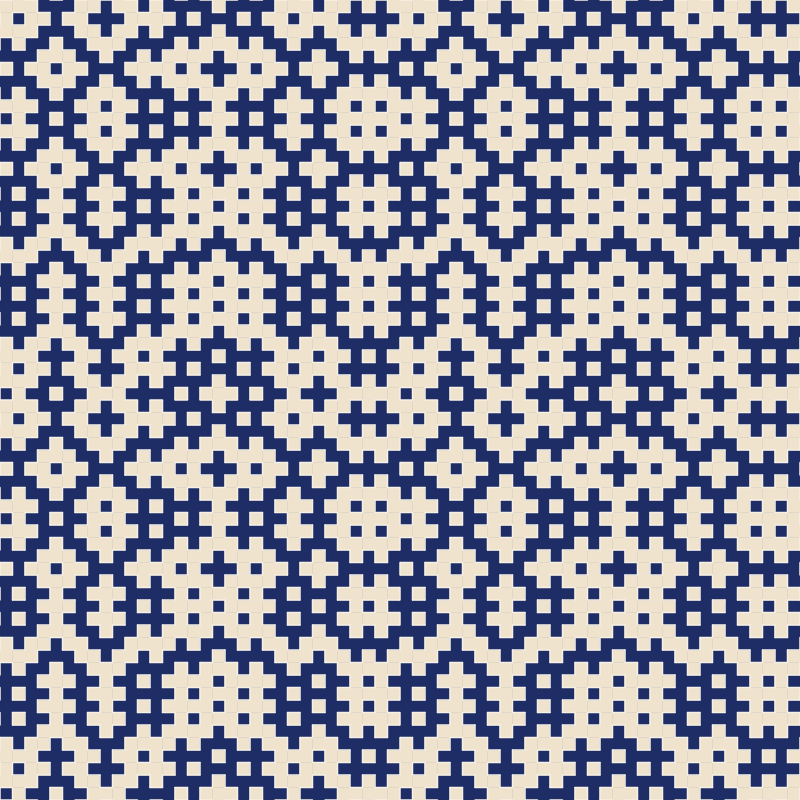

In [5]:
canvas.repeat()

## Try

- Another `SEED`, then run the notebook again from the bits cell down.
- `rows = cols = [i % 2 for i in range(N)]` instead of random bits gives a regular pattern.
- `N = 16` for bigger cells. `N` has to stay even for the tile to repeat.